In [110]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# import tensorflow as tf
# import keras
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import GridSearchCV
import warnings
warnings.simplefilter('ignore')


In [111]:
data = pd.read_csv('pima-indians-diabetes.csv')
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [112]:
data.shape

(768, 9)

In [113]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Class                     768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [114]:
data.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Class'],
      dtype='str')

In [115]:
data.Class.value_counts()

Class
0    500
1    268
Name: count, dtype: int64

In [116]:
data.Pregnancies.value_counts()

Pregnancies
1     135
0     111
2     103
3      75
4      68
5      57
6      50
7      45
8      38
9      28
10     24
11     11
13     10
12      9
14      2
15      1
17      1
Name: count, dtype: int64

In [117]:
data.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Class
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


<Axes: xlabel='Age'>

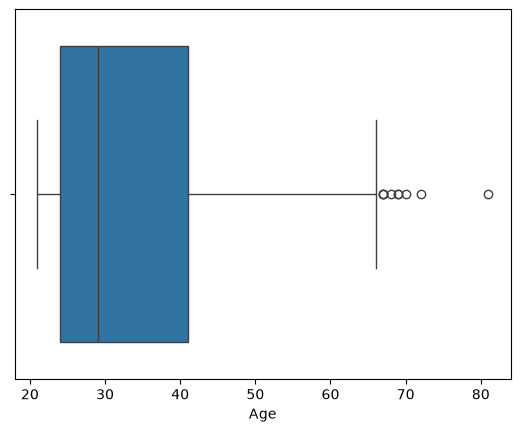

In [118]:
sns.boxplot(x =data.Age)

<Axes: xlabel='Pregnancies', ylabel='count'>

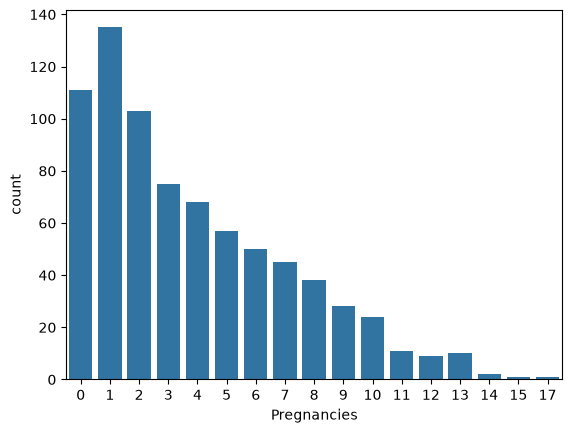

In [119]:
sns.countplot(x=data['Pregnancies'])

<Axes: xlabel='Class', ylabel='count'>

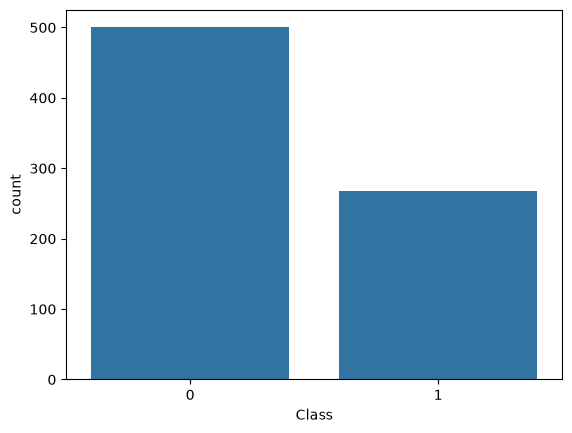

In [120]:
sns.countplot(x =data.Class)

<Axes: xlabel='Insulin'>

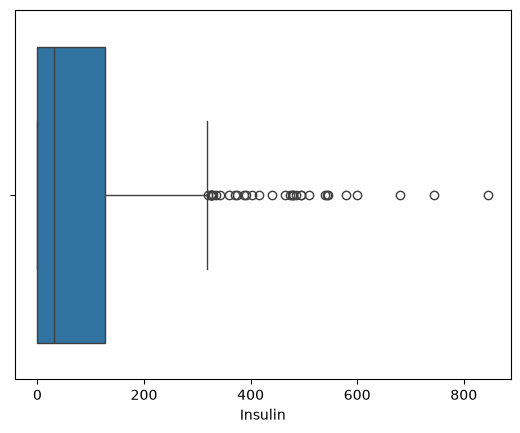

In [121]:
sns.boxplot(x = data.Insulin)

<Axes: xlabel='BMI'>

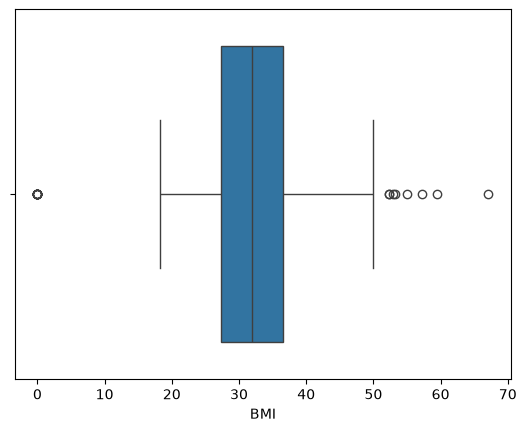

In [122]:
sns.boxplot(x = data.BMI)

<Axes: xlabel='Age', ylabel='BMI'>

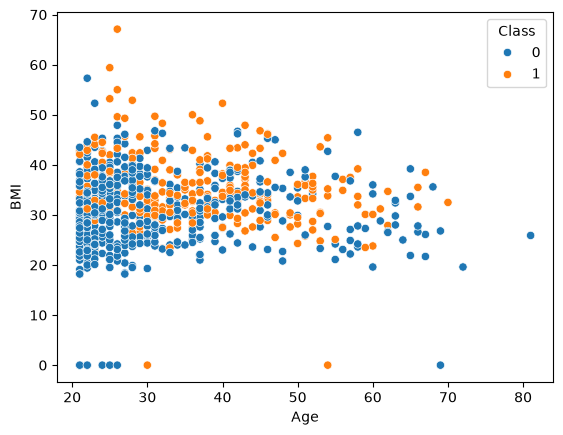

In [123]:
sns.scatterplot(x= 'Age', y = 'BMI', data = data, hue ='Class')

<Axes: xlabel='Age', ylabel='Pregnancies'>

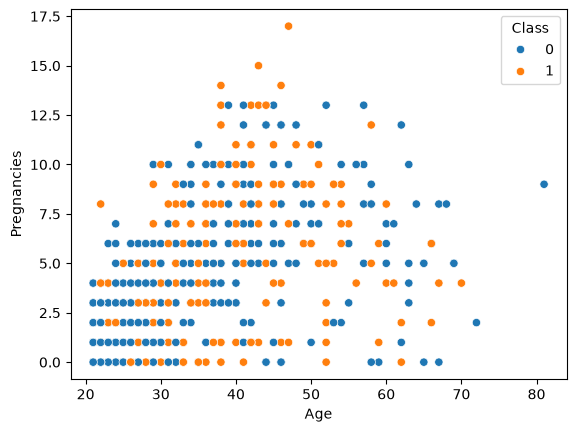

In [124]:
sns.scatterplot(x = 'Age', y = 'Pregnancies', data= data, hue = 'Class')

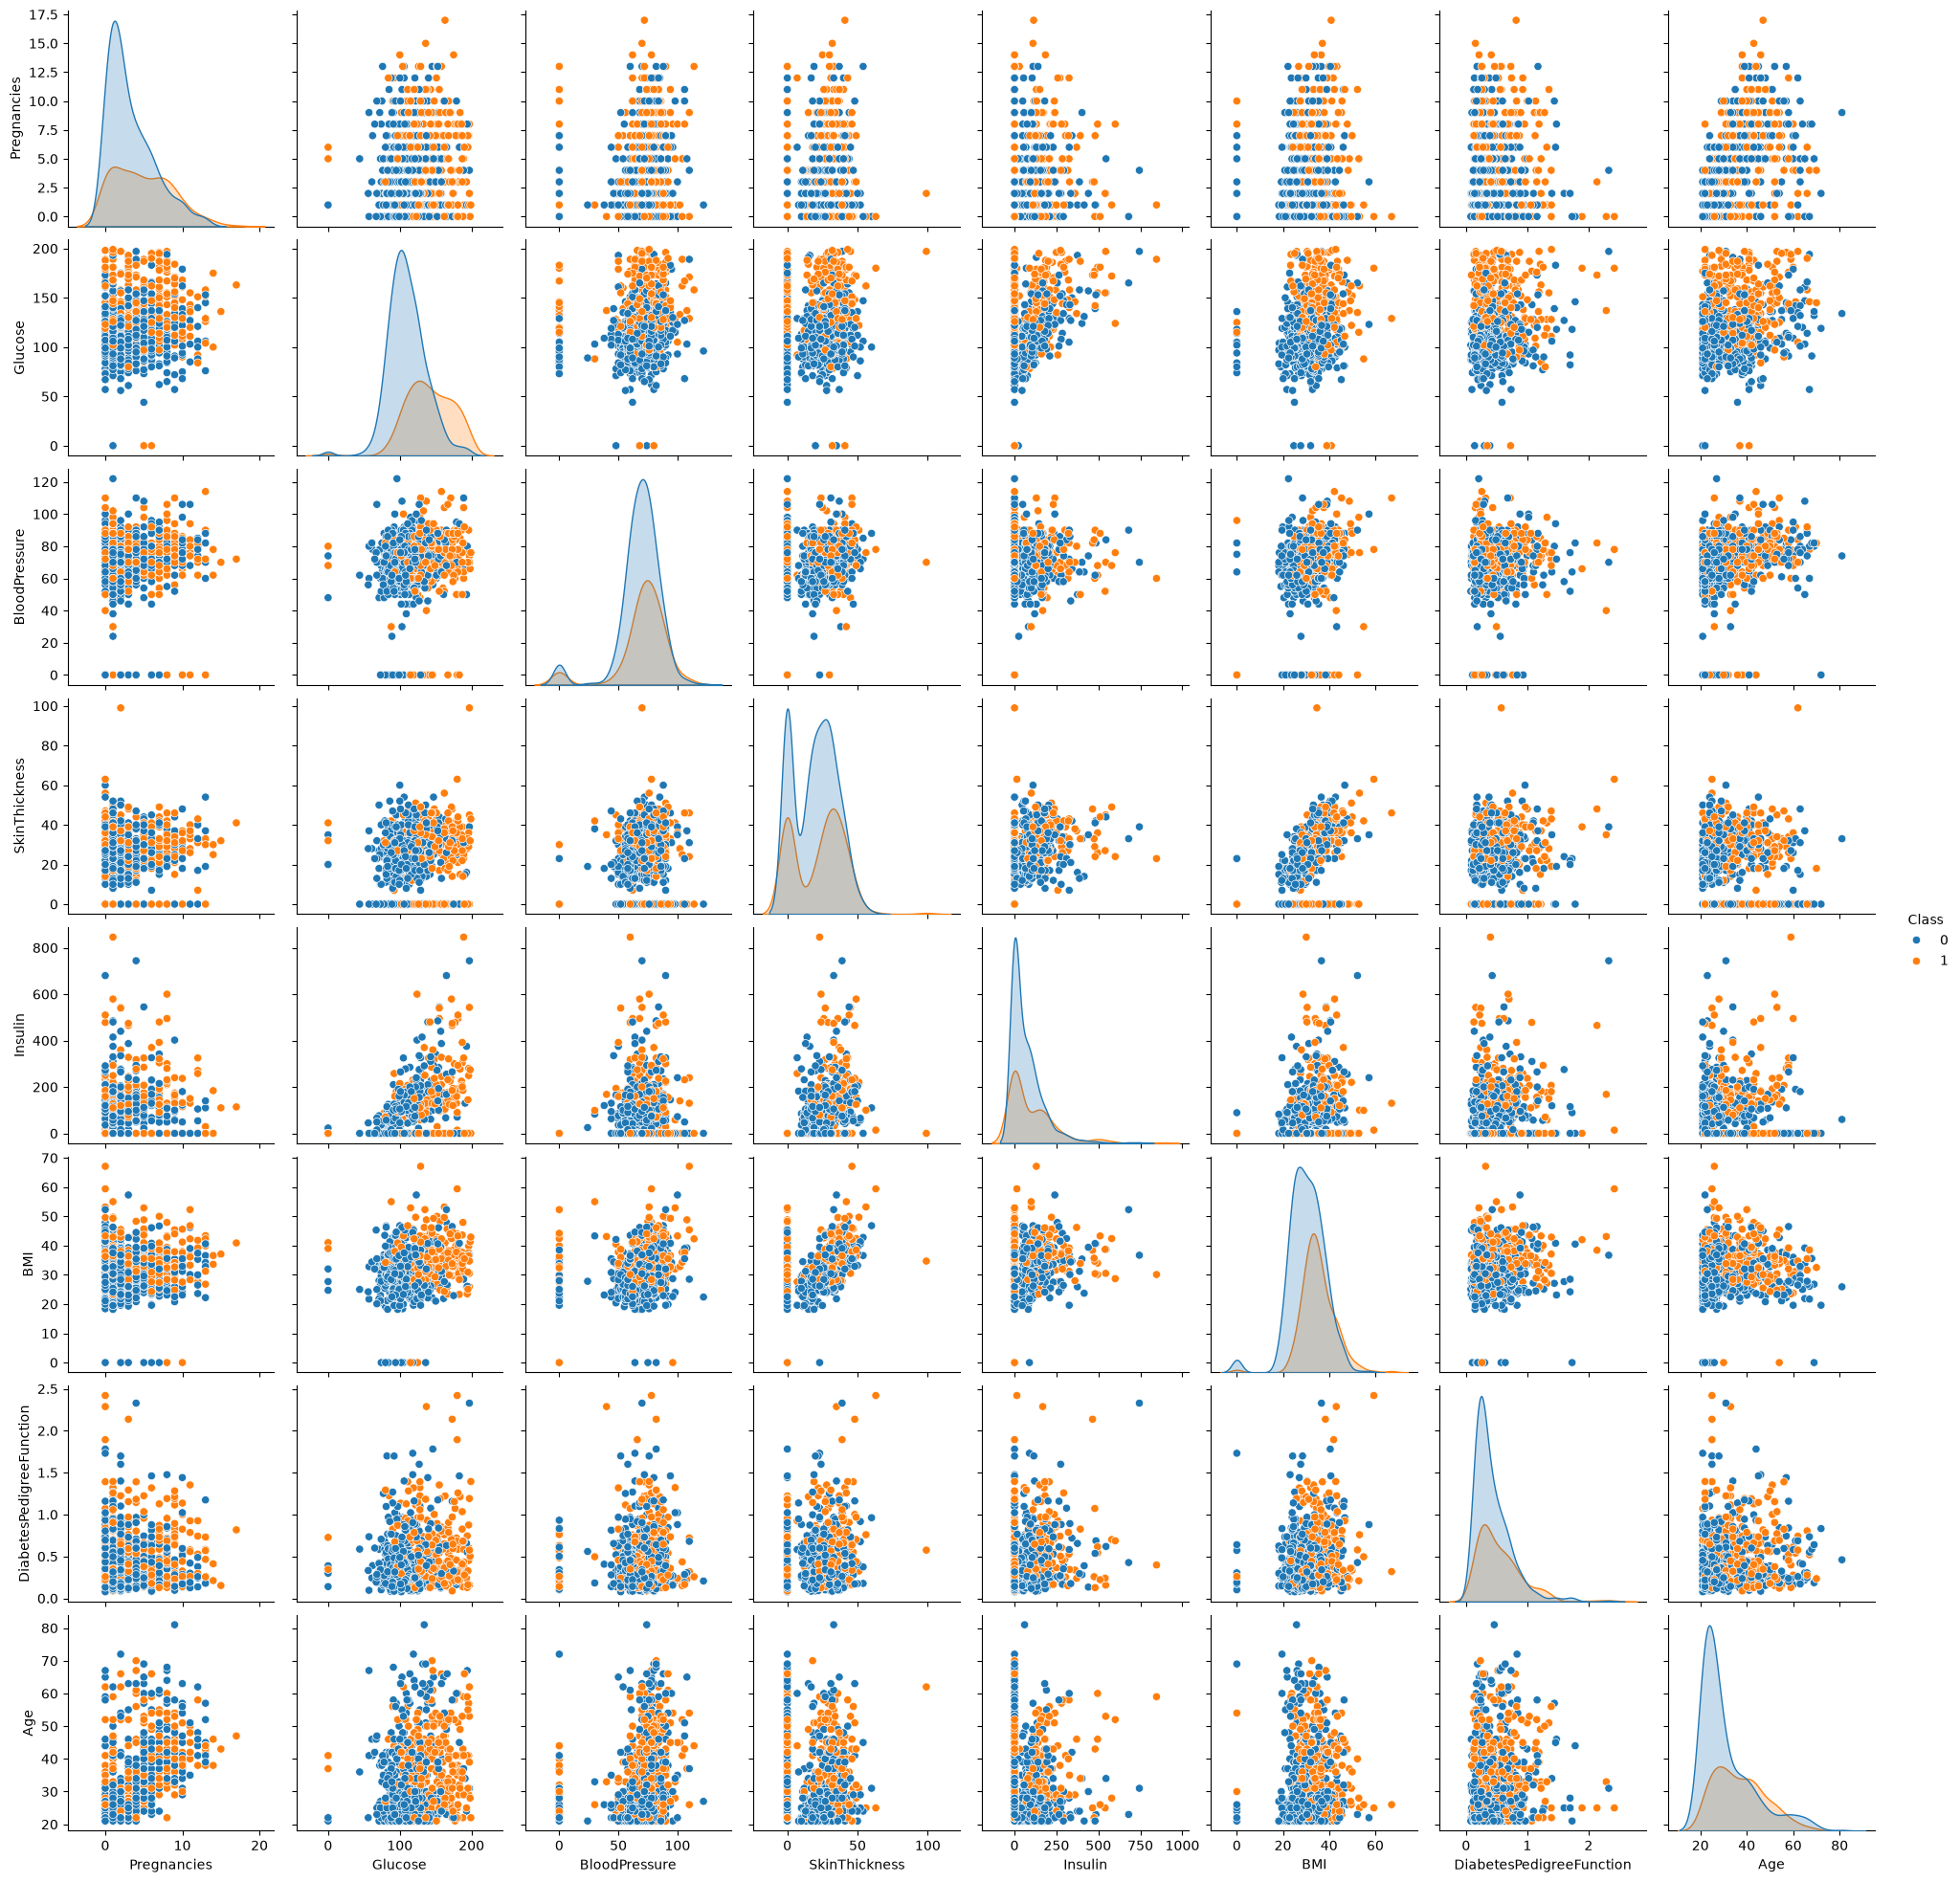

In [125]:
sns.pairplot(data = data, hue = 'Class')

In [126]:
data.corr()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Class
Pregnancies,1.000000,0.129459,0.141282,-0.081672,-0.073535,0.017683,-0.033523,0.544341,0.221898
Glucose,0.129459,1.000000,0.152590,0.057328,0.331357,0.221071,0.137337,0.263514,0.466581
BloodPressure,0.141282,0.152590,1.000000,0.207371,0.088933,0.281805,0.041265,0.239528,0.065068
SkinThickness,-0.081672,0.057328,0.207371,1.000000,0.436783,0.392573,0.183928,-0.113970,0.074752
Insulin,-0.073535,0.331357,0.088933,0.436783,1.000000,0.197859,0.185071,-0.042163,0.130548
BMI,0.017683,0.221071,0.281805,0.392573,0.197859,1.000000,0.140647,0.036242,0.292695
DiabetesPedigreeFunction,-0.033523,0.137337,0.041265,0.183928,0.185071,0.140647,1.000000,0.033561,0.173844
Age,0.544341,0.263514,0.239528,-0.113970,-0.042163,0.036242,0.033561,1.000000,0.238356
Class,0.221898,0.466581,0.065068,0.074752,0.130548,0.292695,0.173844,0.238356,1.000000


<Axes: >

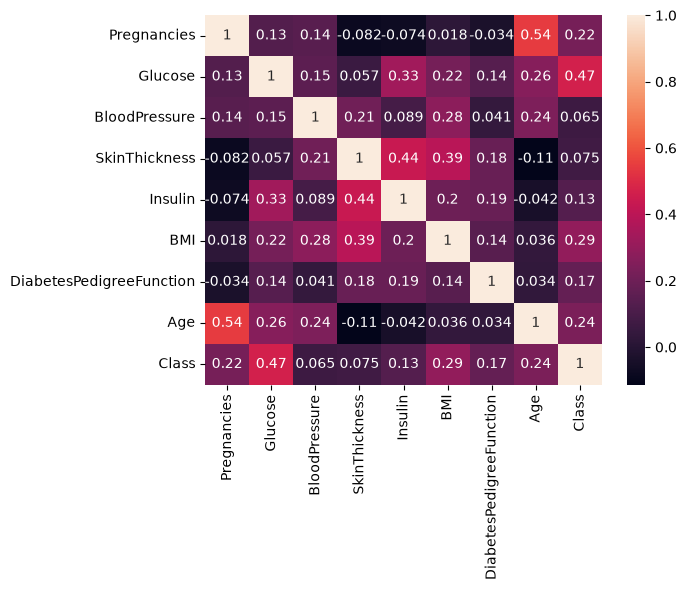

In [127]:
sns.heatmap( data.corr(), annot=True)

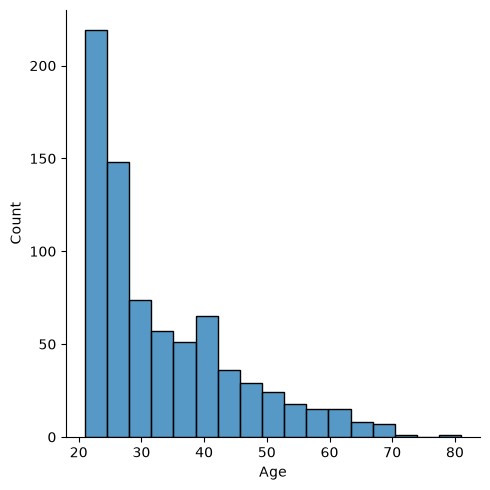

In [128]:
sns.displot(x =data.Age)

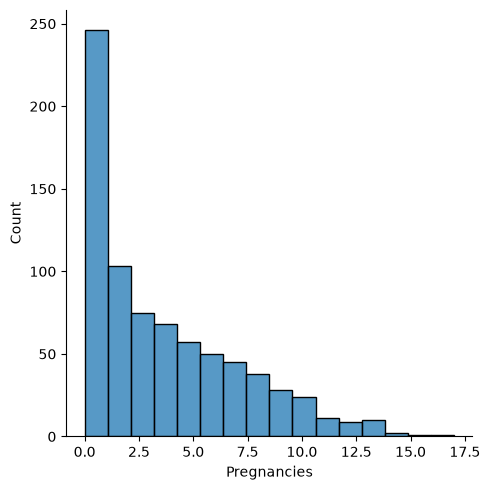

In [129]:
sns.displot(x = data.Pregnancies)

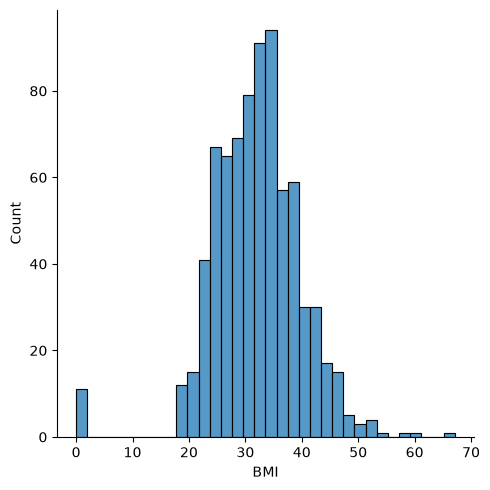

In [130]:
sns.displot(x = data.BMI)

In [131]:
data.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Class                       0
dtype: int64

In [132]:
data.Age.skew()

np.float64(1.1295967011444796)

In [133]:
data.Pregnancies.skew()

np.float64(0.9016739791518584)

In [134]:
data.Glucose.skew()

np.float64(0.17375350179188986)

In [135]:
data.BMI.skew()

np.float64(-0.4289815884535662)

In [136]:
X = data.iloc[:,0:8]
y = data.iloc[:,8]

## **Train Test Split**

In [137]:
x_train, x_test, y_train, y_test = train_test_split(X, y,random_state=101, test_size = 0.3)

In [138]:
y_train

711    0
58     0
216    1
168    0
658    0
      ..
75     0
599    0
575    0
337    1
523    1
Name: Class, Length: 537, dtype: int64

## **Creating piplelines**

- **1 - Data Preprocessing using standard scaler**
- **2 - Reducing Dimensionality using PCA**
- **3 - Training respective models**

In [139]:
# logistic regression pipeline

lr_pipeline = Pipeline([('scale',StandardScaler()),
                        ('pcs', PCA(n_components = 0.95)),
                        ('lr',LogisticRegression())])

#K-NN classifier pipeline

Knn_pipeline = Pipeline([('scale', StandardScaler()),
                         ('pca', PCA(n_components= 0.95)),
                         ('knn', KNeighborsClassifier())])

#Decision tree classifier pipelines

dtc_pipeline = Pipeline([('scale', StandardScaler()),
                         ('pca',PCA(n_components=0.95)),
                         ('DTC', DecisionTreeClassifier())])

# Random forest tree classifier pipeline

rfc_pipeline = Pipeline([('scale', StandardScaler()),
                         ('pca', PCA(n_components = 0.95)),
                         ('rfc', RandomForestClassifier())])

In [140]:
#Gradient boosting classifier pipeline

gbc_pipeline = Pipeline([('scale', StandardScaler()),
                         ('pca', PCA(n_components= 0.95)),
                         ('gbc', GradientBoostingClassifier())])

# XG boost classifier pipeline

xgb_pipeline = Pipeline([('scale', StandardScaler()),
                         ('pca', PCA(n_components= 0.95)),
                         ('xgb', XGBClassifier())])

from sklearn.svm import SVC

#SVM classifier pipeline

svm_pipeline = Pipeline([('scale', StandardScaler()),
                         ('pcs', PCA(n_components=0.95)),
                         ('svm', SVC())])



## **Modelling and evaluation**

In [141]:
# defining the pipelines in a list

mypipeline = [lr_pipeline, Knn_pipeline, dtc_pipeline,rfc_pipeline, gbc_pipeline,xgb_pipeline, svm_pipeline]

In [142]:
# fit the pipelines

for mypipe in mypipeline:
    mypipe.fit(x_train, y_train)

In [143]:
# defining variable for choosing best model

accuracy  = 0.0
classifier = 0
pipeline = ''
test_prediction = ''

In [144]:
# Creating disctory of pipeline and traing models

PipelineDict = {0:'Logistic Regression', 1:'KNN Classifier',2 : 'Decision Tree',
                3:'Random Forest', 4:'Gradient Boost', 5:'XGBoost', 6:"SVM"}

In [145]:
# test prediction

for i, model in enumerate(mypipeline):
    ('{} test prediction: {}'.format(PipelineDict[i], model.predict(x_test)))

In [146]:
# train predict

for i, model in enumerate(mypipeline):
    ('{} train prediction: {}'.format(PipelineDict[i],model.predict(x_train)))

## **Test accuracy**

In [147]:
for i, model in enumerate(mypipeline):
    print('{} train accuracy: {}'.format(PipelineDict[i], model.score(x_train, y_train)))
    print('{} test accuracy:  {}'.format(PipelineDict[i], model.score(x_test, y_test)))

print("*"*50)

Logistic Regression train accuracy: 0.7802607076350093
Logistic Regression test accuracy:  0.7878787878787878
KNN Classifier train accuracy: 0.813780260707635
KNN Classifier test accuracy:  0.7619047619047619
Decision Tree train accuracy: 1.0
Decision Tree test accuracy:  0.7359307359307359
Random Forest train accuracy: 1.0
Random Forest test accuracy:  0.7619047619047619
Gradient Boost train accuracy: 0.9404096834264432
Gradient Boost test accuracy:  0.7835497835497836
XGBoost train accuracy: 1.0
XGBoost test accuracy:  0.7445887445887446
SVM train accuracy: 0.8249534450651769
SVM test accuracy:  0.7835497835497836
**************************************************


## **best model for accuracy wise**

In [148]:
## chhosing best model for given data

for j, model in enumerate(mypipeline):
    if model.score(x_test, y_test)>accuracy:
        accuracy = model.score(x_test, y_test)
        pipeline = model
        classifier = j

print('Classifier with best accuaracy: {}'.format(PipelineDict[classifier]))

Classifier with best accuaracy: Logistic Regression


## **confusion matrics**

In [149]:
from sklearn.metrics import classification_report,  accuracy_score

In [150]:
for j, model in enumerate(mypipeline):
    print('{}'.format(PipelineDict[j]))
plt.show()

Logistic Regression
KNN Classifier
Decision Tree
Random Forest
Gradient Boost
XGBoost
SVM


In [151]:
cv = cross_val_score(LogisticRegression, X, y, cv= 5)
print(cv)
cv.mean

TypeError: Expected an estimator instance (LogisticRegression()), got estimator class instead (LogisticRegression).

In [152]:
def find_best_model(X,y):
    models = {'lr':{'model':LogisticRegression(),
              'param_grid':{'penalty':['l2','l1']}},
              
              'xgb':{'model':XGBClassifier(),
                     'param_grid':{'n_estimators': [1,5,8,10,15,40,100],
                                      'max_depth':[3,4,5],
                                     'gamma':[0,0.1,0.2,.3,1,2,3] }},
              
               'gbc':{'model':GradientBoostingClassifier(),
                     'param_grid':{'n_estimators': list(range(1,50)),
                         'learning_rate':[.1,.2,.3,.4,.5,.8,1]}},
              
              'svc':{'model':SVC(),
                    'param_grid':{'C':[0.1,0.2,1.0,2.0,3.0,4.0],
                         'kernel':['rbf','sigmoid','poly','linear']}},
              
              'dtc':{'model':DecisionTreeClassifier(),
                     'param_grid':{'criterion':["gini", "entropy"],
                       'max_depth':[1,2,3,4,5,6] }},
              
              'rfc':{'model':RandomForestClassifier(random_state=1),
                     'param_grid':{'n_estimators':list(range(1,50)),
                                  'criterion':["gini", "entropy"]}},
               
              'knn':{'model':KNeighborsClassifier(algorithm='auto'),
                     'param_grid':{'n_neighbors':list(range(1,50)),
                                  'p':[1,2]}}}
            
    scores = []
    for model_name,model_params in models.items():
            gs= GridSearchCV(model_params['model'],
                             model_params['param_grid'],
                             cv=5,return_train_score = False)
            gs.fit(X,y)
            scores.append({'model':model_name,
                          'best_parameters':gs.best_params_,
                          'score':gs.best_score_})
    return pd.DataFrame(scores,columns=['model','best_parameters','score'])

In [153]:
find_best_model(X,y)  

,model,best_parameters,score
0,lr,{'penalty': 'l2'},0.768262
1,xgb,"{'gamma': 0.1, 'max_depth': 3, 'n_estimators':...",0.772218
2,gbc,"{'learning_rate': 0.2, 'n_estimators': 48}",0.779985
3,svc,"{'C': 4.0, 'kernel': 'linear'}",0.770885
4,dtc,"{'criterion': 'gini', 'max_depth': 5}",0.748782
5,rfc,"{'criterion': 'gini', 'n_estimators': 33}",0.770868
6,knn,"{'n_neighbors': 14, 'p': 1}",0.766930
